In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")
%matplotlib inline

In [27]:
df=pd.read_excel('Flight_Fare.xlsx')

In [28]:
df.head()

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
0,IndiGo,24/03/2019,Banglore,New Delhi,BLR → DEL,22:20,01:10 22 Mar,2h 50m,non-stop,No info,3897
1,Air India,1/05/2019,Kolkata,Banglore,CCU → IXR → BBI → BLR,05:50,13:15,7h 25m,2 stops,No info,7662
2,Jet Airways,9/06/2019,Delhi,Cochin,DEL → LKO → BOM → COK,09:25,04:25 10 Jun,19h,2 stops,No info,13882
3,IndiGo,12/05/2019,Kolkata,Banglore,CCU → NAG → BLR,18:05,23:30,5h 25m,1 stop,No info,6218
4,IndiGo,01/03/2019,Banglore,New Delhi,BLR → NAG → DEL,16:50,21:35,4h 45m,1 stop,No info,13302


In [29]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10683 entries, 0 to 10682
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Airline          10683 non-null  object
 1   Date_of_Journey  10683 non-null  object
 2   Source           10683 non-null  object
 3   Destination      10683 non-null  object
 4   Route            10682 non-null  object
 5   Dep_Time         10683 non-null  object
 6   Arrival_Time     10683 non-null  object
 7   Duration         10683 non-null  object
 8   Total_Stops      10682 non-null  object
 9   Additional_Info  10683 non-null  object
 10  Price            10683 non-null  int64 
dtypes: int64(1), object(10)
memory usage: 918.2+ KB


In [30]:
df.shape

(10683, 11)

In [31]:
df.describe

<bound method NDFrame.describe of            Airline Date_of_Journey    Source Destination  \
0           IndiGo      24/03/2019  Banglore   New Delhi   
1        Air India       1/05/2019   Kolkata    Banglore   
2      Jet Airways       9/06/2019     Delhi      Cochin   
3           IndiGo      12/05/2019   Kolkata    Banglore   
4           IndiGo      01/03/2019  Banglore   New Delhi   
...            ...             ...       ...         ...   
10678     Air Asia       9/04/2019   Kolkata    Banglore   
10679    Air India      27/04/2019   Kolkata    Banglore   
10680  Jet Airways      27/04/2019  Banglore       Delhi   
10681      Vistara      01/03/2019  Banglore   New Delhi   
10682    Air India       9/05/2019     Delhi      Cochin   

                       Route Dep_Time  Arrival_Time Duration Total_Stops  \
0                  BLR → DEL    22:20  01:10 22 Mar   2h 50m    non-stop   
1      CCU → IXR → BBI → BLR    05:50         13:15   7h 25m     2 stops   
2      DEL → LKO 

In [32]:
df.isnull().sum()

Airline            0
Date_of_Journey    0
Source             0
Destination        0
Route              1
Dep_Time           0
Arrival_Time       0
Duration           0
Total_Stops        1
Additional_Info    0
Price              0
dtype: int64

In [33]:
df.dropna(inplace=True)

In [34]:
df.isnull().sum()

Airline            0
Date_of_Journey    0
Source             0
Destination        0
Route              0
Dep_Time           0
Arrival_Time       0
Duration           0
Total_Stops        0
Additional_Info    0
Price              0
dtype: int64

 EXPLORATORY DATA ANALYSIS (EDA)

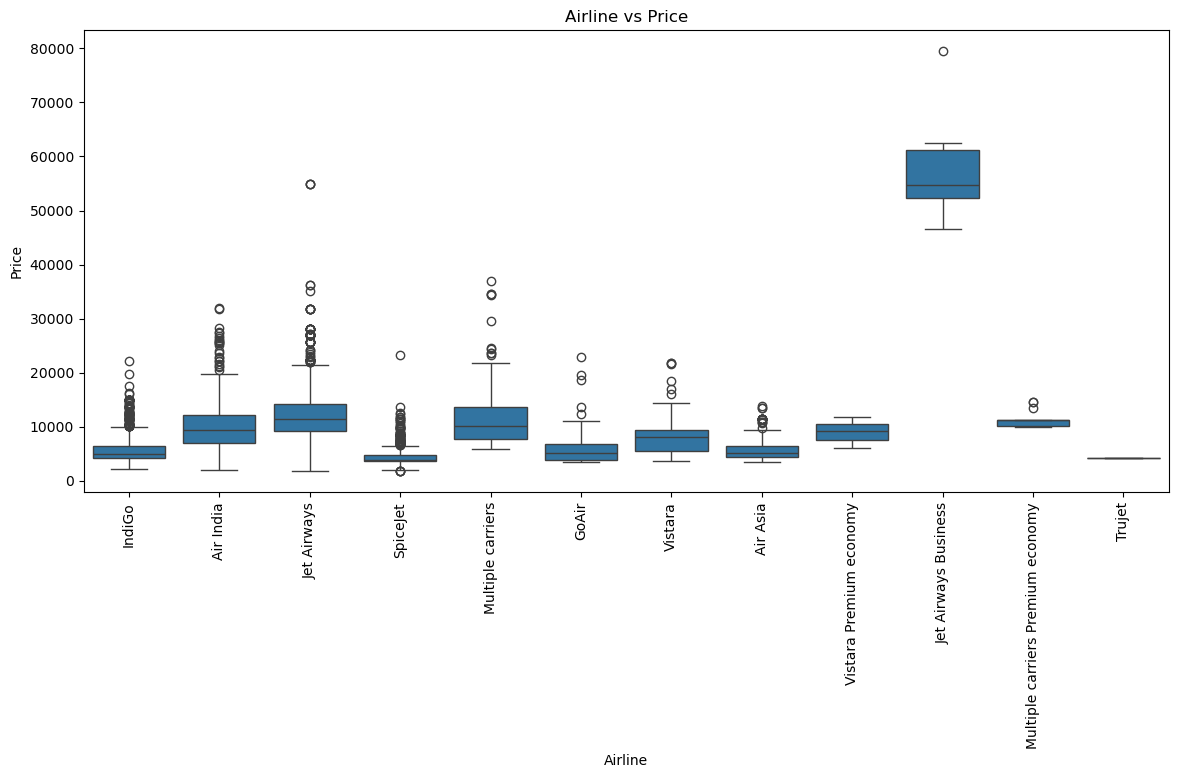

In [35]:
plt.figure(figsize=(14,6))
sns.boxplot(x='Airline', y='Price', data=df)
plt.xticks(rotation=90)
plt.title("Airline vs Price")
plt.show()

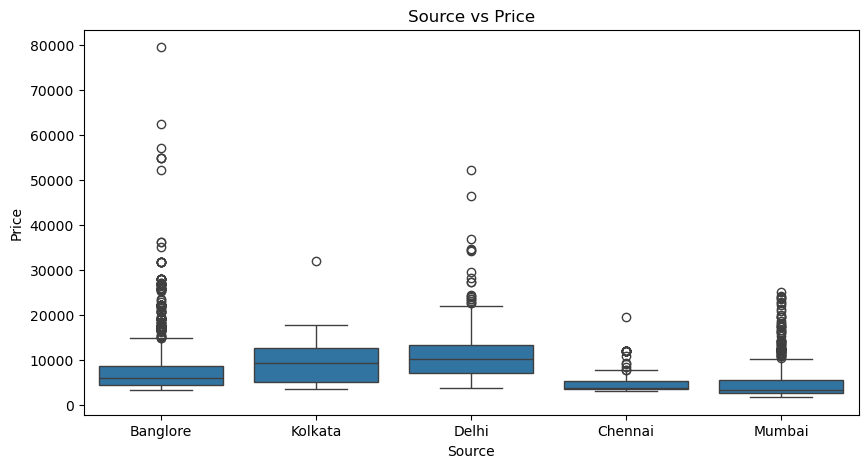

In [36]:
plt.figure(figsize=(10,5))
sns.boxplot(x='Source', y='Price', data=df)
plt.title("Source vs Price")
plt.show()

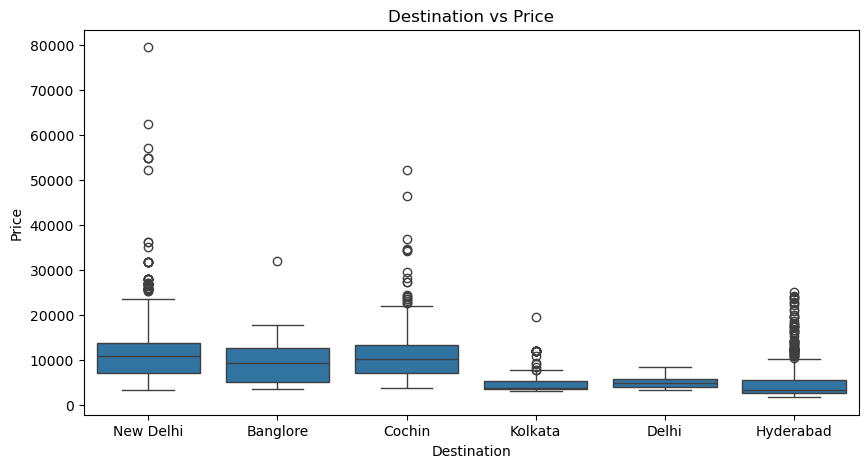

In [37]:
plt.figure(figsize=(10,5))
sns.boxplot(x='Destination', y='Price', data=df)
plt.title("Destination vs Price")
plt.show()

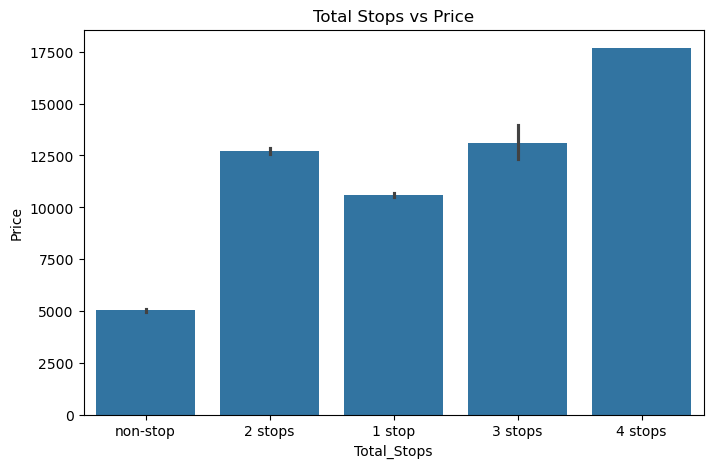

In [38]:
plt.figure(figsize=(8,5))
sns.barplot(x='Total_Stops', y='Price', data=df)
plt.title("Total Stops vs Price")
plt.show()

FEATURE ENGINEERING

In [39]:
df['Date']=df['Date_of_Journey'].str.split('/').str[0]
df[ 'Month' ]=df['Date_of_Journey'].str.split('/').str[1]
df[ 'Year']=df['Date_of_Journey'].str.split('/').str[2]

In [40]:
df.head(2)

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price,Date,Month,Year
0,IndiGo,24/03/2019,Banglore,New Delhi,BLR → DEL,22:20,01:10 22 Mar,2h 50m,non-stop,No info,3897,24,03,2019
1,Air India,1/05/2019,Kolkata,Banglore,CCU → IXR → BBI → BLR,05:50,13:15,7h 25m,2 stops,No info,7662,1,05,2019


In [41]:
df.drop(["Date_of_Journey"], axis=1, inplace=True)

In [42]:
df['Dep_hour']=df['Dep_Time'].str.split(':').str[0]
df['Dep_min']=df['Dep_Time'].str.split(':').str[1]

In [43]:
df.head(1)

,Airline,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price,Date,Month,Year,Dep_hour,Dep_min
0,IndiGo,Banglore,New Delhi,BLR → DEL,22:20,01:10 22 Mar,2h 50m,non-stop,No info,3897,24,03,2019,22,20


In [44]:
df.drop(['Dep_Time'],axis=1, inplace=True)

In [45]:
df.head(1)

,Airline,Source,Destination,Route,Arrival_Time,Duration,Total_Stops,Additional_Info,Price,Date,Month,Year,Dep_hour,Dep_min
0,IndiGo,Banglore,New Delhi,BLR → DEL,01:10 22 Mar,2h 50m,non-stop,No info,3897,24,03,2019,22,20


In [46]:
df['Arrival_hour'] = df['Arrival_Time'].str.split(' ').str[0].str.split(':').str[0]

df['Arrival_min'] = df['Arrival_Time'].str.split(' ').str[0].str.split(':').str[1]

In [47]:
df.head(1)

,Airline,Source,Destination,Route,Arrival_Time,Duration,Total_Stops,Additional_Info,Price,Date,Month,Year,Dep_hour,Dep_min,Arrival_hour,Arrival_min
0,IndiGo,Banglore,New Delhi,BLR → DEL,01:10 22 Mar,2h 50m,non-stop,No info,3897,24,03,2019,22,20,01,10


In [48]:
df.drop(['Arrival_Time'],axis=1,inplace=True)

In [49]:
df.head(1)

,Airline,Source,Destination,Route,Duration,Total_Stops,Additional_Info,Price,Date,Month,Year,Dep_hour,Dep_min,Arrival_hour,Arrival_min
0,IndiGo,Banglore,New Delhi,BLR → DEL,2h 50m,non-stop,No info,3897,24,03,2019,22,20,01,10


In [58]:
Duration=list(df['Duration'])
for i in range(len(Duration)):
    if len(Duration[i].split()) != 2:
        if "h" in Duration[i]:
            Duration[i] = Duration[i] + " 0m"
        else:
            Duration[i] = "0h " + Duration[i]
            Duration_hours = []
            Duration_mins = []


In [59]:
for i in range(len(Duration)):

    Duration_hours.append(
        int(Duration[i].split(sep="h")[0])
    )

    Duration_mins.append(
        int(Duration[i].split(sep="m")[0].split()[-1])
    )

df["Duration_hours"] = Duration_hours
df["Duration_mins"] = Duration_mins

In [60]:
df.drop('Duration',axis=1,inplace=True)

In [61]:
df.head(1)

,Airline,Source,Destination,Route,Total_Stops,Additional_Info,Price,Date,Month,Year,Dep_hour,Dep_min,Arrival_hour,Arrival_min,Duration_hours,Duration_mins
0,IndiGo,Banglore,New Delhi,BLR → DEL,non-stop,No info,3897,24,03,2019,22,20,01,10,2,50


HANDLE CATEGORICAL DATA

In [62]:
Airline = pd.get_dummies(
df["Airline"],
drop_first=True
)

In [63]:
Source = pd.get_dummies(
df["Source"],
drop_first=True
)

In [64]:
Destination = pd.get_dummies(
df["Destination"],
drop_first=True
)

In [65]:
df.drop(["Airline", "Source", "Destination"],axis=1,inplace=True)

In [69]:
df = pd.concat([df, Airline, Source, Destination],axis=1)

In [71]:
df.head(5)

,Route,Total_Stops,Additional_Info,Price,Date,Month,Year,Dep_hour,Dep_min,Arrival_hour,...,Vistara Premium economy,Chennai,Delhi,Kolkata,Mumbai,Cochin,Delhi,Hyderabad,Kolkata,New Delhi
0,BLR → DEL,non-stop,No info,3897,24,03,2019,22,20,01,...,False,False,False,False,False,False,False,False,False,True
1,CCU → IXR → BBI → BLR,2 stops,No info,7662,1,05,2019,05,50,13,...,False,False,False,True,False,False,False,False,False,False
2,DEL → LKO → BOM → COK,2 stops,No info,13882,9,06,2019,09,25,04,...,False,False,True,False,False,True,False,False,False,False
3,CCU → NAG → BLR,1 stop,No info,6218,12,05,2019,18,05,23,...,False,False,False,True,False,False,False,False,False,False
4,BLR → NAG → DEL,1 stop,No info,13302,01,03,2019,16,50,21,...,False,False,False,False,False,False,False,False,False,True


HANDLE TOTAL STOPS

In [72]:
df["Total_Stops"] = df["Total_Stops"].map({
"non-stop": 0,
"1 stop": 1,
"2 stops": 2,
"3 stops": 3,
"4 stops": 4
})

DROP UNNECESSARY COLUMNS

In [ ]:
df.drop(
["Route", "Additional_Info"],
axis=1,
inplace=True
)

FINAL DATASET

In [77]:
print("\nFinal Dataset")
print(df.head())
print("\nFinal Shape")
print(df.shape)


Final Dataset
   Total_Stops  Price Date Month  Year Dep_hour Dep_min Arrival_hour  \
0            0   3897   24    03  2019       22      20           01   
1            2   7662    1    05  2019       05      50           13   
2            2  13882    9    06  2019       09      25           04   
3            1   6218   12    05  2019       18      05           23   
4            1  13302   01    03  2019       16      50           21   

  Arrival_min  Duration_hours  ...  Vistara Premium economy  Chennai  Delhi  \
0          10               2  ...                    False    False  False   
1          15               7  ...                    False    False  False   
2          25              19  ...                    False    False   True   
3          30               5  ...                    False    False  False   
4          35               4  ...                    False    False  False   

   Kolkata  Mumbai  Cochin  Delhi  Hyderabad  Kolkata  New Delhi  
0    False

CORRELATION HEATMAP

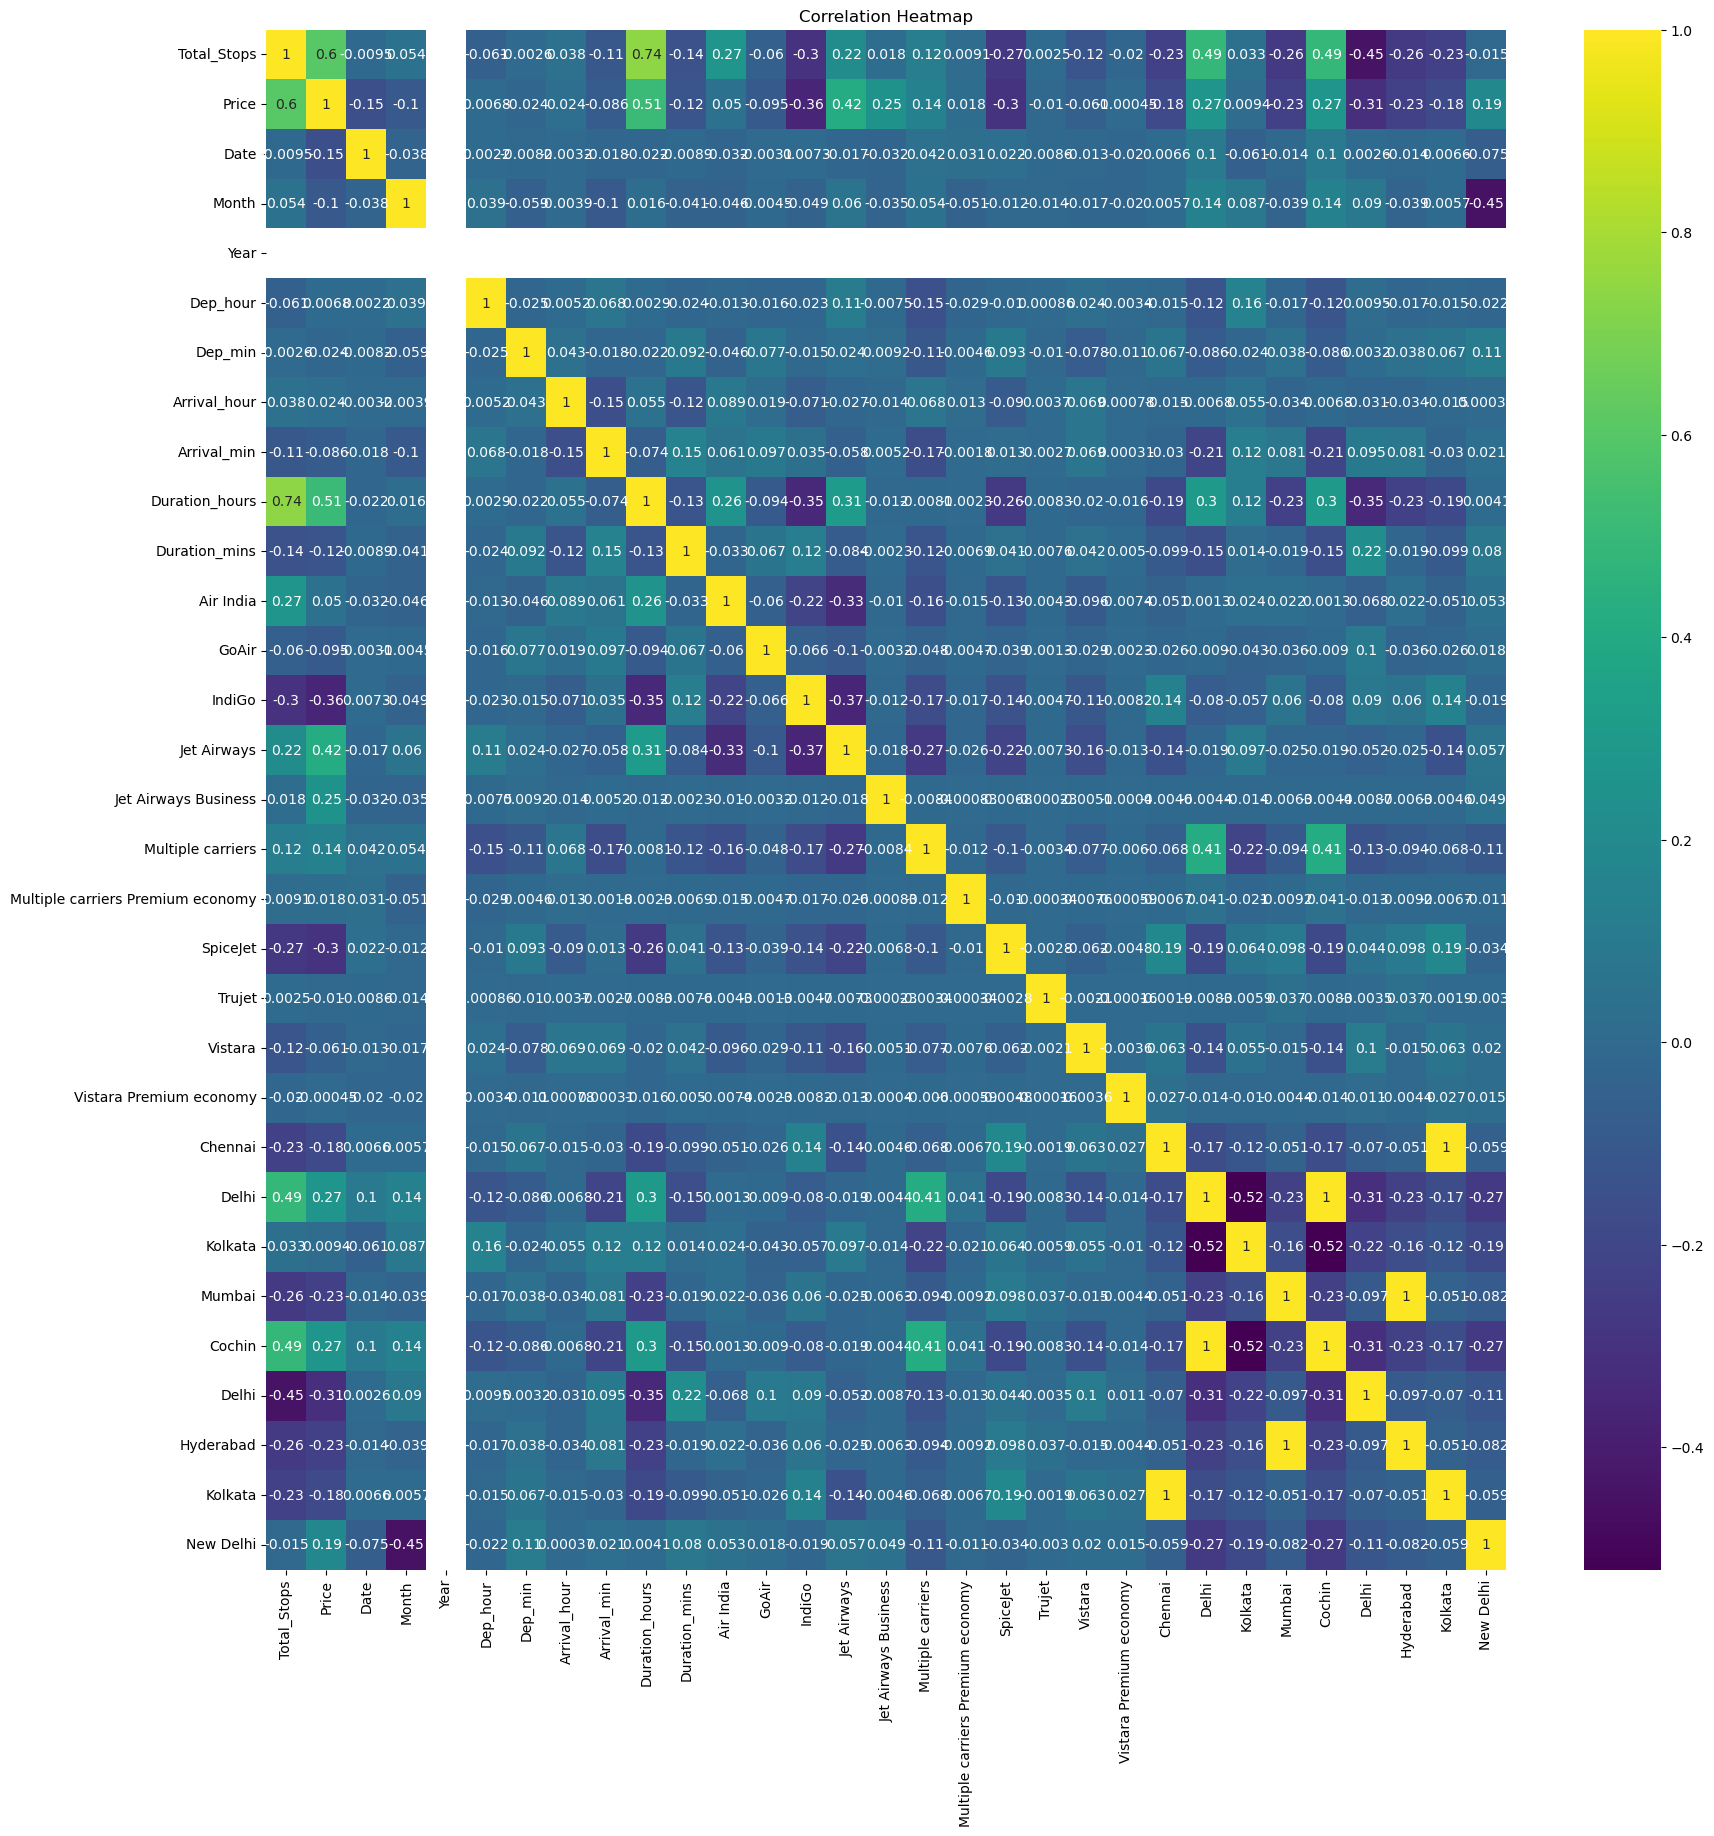

In [78]:
plt.figure(figsize=(20,20))
sns.heatmap(df.corr(), annot=True, cmap="viridis")
plt.title("Correlation Heatmap")
plt.show()

SPLIT DATA

In [81]:
from sklearn.model_selection import train_test_split
X = df.drop(["Price"], axis=1)
y = df["Price"]
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)

LINEAR REGRESSION MODEL

In [85]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
import numpy as np
lr = LinearRegression()
lr.fit(X_train, y_train)
y_pred_lr = lr.predict(X_test)
print("\n==============================")
print("LINEAR REGRESSION RESULTS")
print("==============================")
print("MAE :", mean_absolute_error(y_test, y_pred_lr))
print("MSE :", mean_squared_error(y_test, y_pred_lr))
print("RMSE :", np.sqrt(mean_squared_error(y_test, y_pred_lr)))
print("R2 Score :", r2_score(y_test, y_pred_lr))


LINEAR REGRESSION RESULTS
MAE : 1972.937285514806
MSE : 8202327.557407149
RMSE : 2863.9705929717834
R2 Score : 0.6195943729070094


In [87]:
from sklearn.ensemble import RandomForestRegressor
rf = RandomForestRegressor()
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)
print("\n==============================")
print("RANDOM FOREST RESULTS")
print("==============================")
print("MAE :", mean_absolute_error(y_test, y_pred_rf))
print("MSE :", mean_squared_error(y_test, y_pred_rf))
print("RMSE :", np.sqrt(mean_squared_error(y_test, y_pred_rf)))
print("R2 Score :", r2_score(y_test, y_pred_rf))


RANDOM FOREST RESULTS
MAE : 1175.1754230597824
MSE : 4370652.466835655
RMSE : 2090.610548819568
R2 Score : 0.7972989031691734


FEATURE IMPORTANCE


Feature Importance
                              Feature  Importance
8                      Duration_hours    0.443050
1                                Date    0.126356
13                        Jet Airways    0.064069
2                               Month    0.063037
14               Jet Airways Business    0.061248
6                        Arrival_hour    0.036715
0                         Total_Stops    0.035530
4                            Dep_hour    0.029515
5                             Dep_min    0.022413
7                         Arrival_min    0.021051
15                  Multiple carriers    0.020965
9                       Duration_mins    0.020190
29                          New Delhi    0.016605
12                             IndiGo    0.006306
10                          Air India    0.005481
23                            Kolkata    0.004876
24                             Mumbai    0.003774
27                          Hyderabad    0.003431
19                            

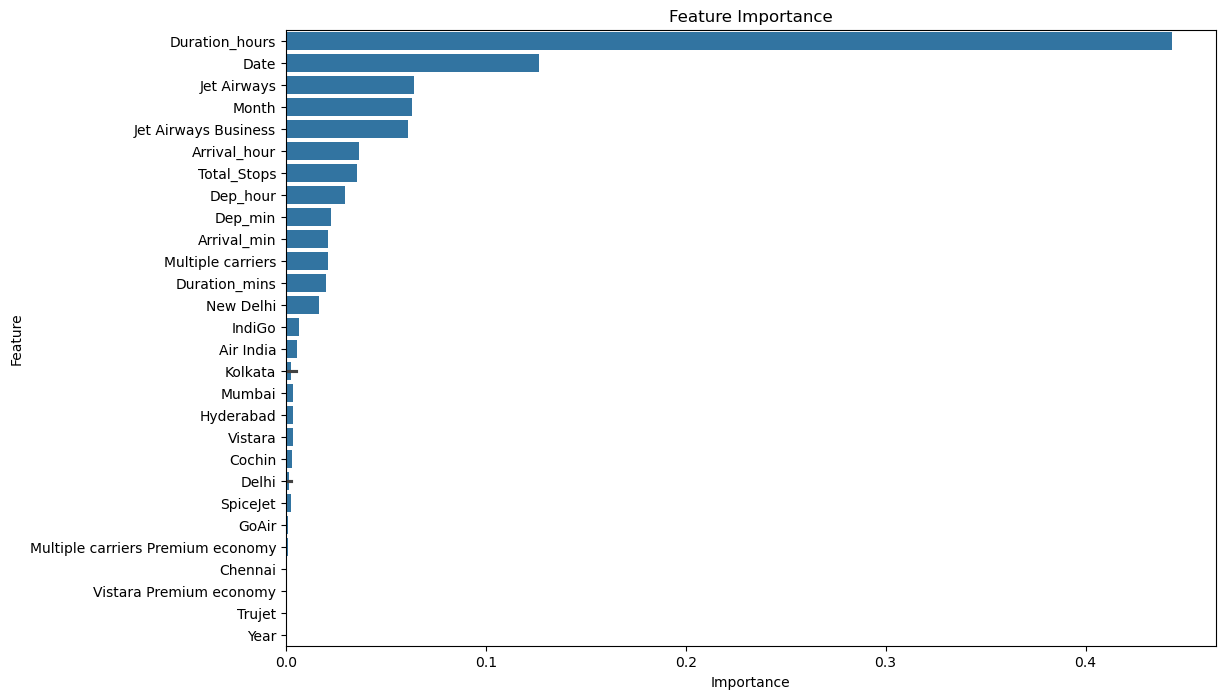

In [88]:
importance = rf.feature_importances_
feature_importance = pd.DataFrame({
'Feature': X_train.columns,
'Importance': importance
})
feature_importance = feature_importance.sort_values(
by='Importance',
ascending=False
)
print("\nFeature Importance")
print(feature_importance)
plt.figure(figsize=(12,8))
sns.barplot(
x='Importance',
y='Feature',
data=feature_importance
)
plt.title("Feature Importance")
plt.show()

SAMPLE PREDICTION

In [89]:
sample_prediction = rf.predict(X_test)
print("\nSample Predictions")
print(sample_prediction[:10])


Sample Predictions
[16809.06        5455.41        8849.08        3683.05
 15056.91183333  9757.6475     13206.50566667  5677.44047619
 14227.80183333 13763.9525    ]


FINAL CONCLUSION

In [93]:
print("""
==================================================
FINAL CONCLUSION
==================================================
1. Random Forest gives better accuracy compared
to Linear Regression.
2. Duration and Airline are important factors
affecting flight prices.
3. More stops usually affect ticket fare.
4. Flight prices vary based on source and
destination cities.
5. Random Forest is recommended for production.
==================================================
""")

Final Conclusion
